## Thanks to the SCIMBA team (E. Franck, V. Michel-Dansac, ...)  

https://www.scimba.org

----------------------------------------------------------------
# PINN

In this tutorial we will see how to define a simple PINN in the disk and how to change the BCs.
    

In [1]:
from collections import OrderedDict

import matplotlib.pyplot as plt
import torch

from scimba_torch.approximation_space.nn_space import NNxSpace
from scimba_torch.domain.meshless_domain.domain_2d import ArcCircle2D, Disk2D
from scimba_torch.integration.monte_carlo import DomainSampler, TensorizedSampler
from scimba_torch.integration.monte_carlo_parameters import UniformParametricSampler
from scimba_torch.neural_nets.coordinates_based_nets.mlp import GenericMLP
from scimba_torch.numerical_solvers.elliptic_pde.pinns import (
    AnagramPinnsElliptic,
    NaturalGradientPinnsElliptic,
    PinnsElliptic,
)
from scimba_torch.optimizers.optimizers_data import OptimizerData
from scimba_torch.physical_models.elliptic_pde.abstract_elliptic_pde import (
    StrongFormEllipticPDE,
)
from scimba_torch.plots.plots_nd import plot_abstract_approx_spaces
from scimba_torch.utils.scimba_tensors import LabelTensor, MultiLabelTensor

## Problem
We desire to solve the Poisson problem in the disk $\mathcal D=\{x^2+y^2\leq 1\}$
$$
-\mu \Delta u(x,y) = f (x,y)
$$
with homogogenous Dirichlet boundary conditions (bcs)
$$
u(x,y)=0 \mbox{ for }(x,y)\in \partial \mathcal D=\{x^2+y^2=1 \}.
$$
We will also consider homogogenous Dirichlet boundary conditions (bcs)
$u(x,y)=0$ on the upper part of $ \partial \mathcal D$, complemented with 
non homogenous boundary conditions on the lower part of the boundary
$$
\partial _n u(x,y)= \left( \nabla u \cdot n \right) (x,y)=g, \quad
(x,y)\in \mathcal D \mbox{ and } y<0.
$$

In [2]:
domain_mu = [[1.0, 2.0]]
domain_x = Disk2D((0.0, 0.0), 1, is_main_domain=True)
disk_up = ArcCircle2D((0.0, 0.0), 1, 0.0, torch.pi)
disk_do = ArcCircle2D((0.0, 0.0), 1, torch.pi, 2 * torch.pi)
domain_x.add_bc_domain(disk_up)
domain_x.add_bc_domain(disk_do)

sampler = TensorizedSampler(
    [DomainSampler(domain_x), UniformParametricSampler(domain_mu)]
)


# xnbc, mubc = sampler.bc_sample(60, index_bc=0)
# xbc, nbc = xnbc[0], xnbc[1]
# print("len(xnbc): ", len(xnbc))
# print("xbc: ", xbc)
# print("nbc: ", nbc)
# print("mubc: ", mubc)


space = NNxSpace(
    1,
    1,
    GenericMLP,
    domain_x,
    sampler,
    layer_sizes=[40, 40, 40, 40],
)


## A simple PINN approach
Our goal is to minimize Loss functions like
$$
J=\int_{\mathcal D} \left|\mu \Delta u (x,y)+f(x,y) \right|^2 dxdy
+\lambda \int_{\partial \mathcal D } |u(x,y)|^2 d\sigma.
$$
The first step is to define a convenient class below.

Detail the lines which define the "$\rm \bf  operator$" and the "$\rm \bf bc-operator$".

In [3]:
class Laplacian2DMixedBCStrongForm(StrongFormEllipticPDE):
    def __init__(self, space, f, g, **kwargs):
        super().__init__(
            space, residual_size=1, bc_residual_size=2, linear=True, **kwargs
        )
        self.f = f
        self.g = g

    def rhs(self, w, x, mu):
        return self.f(x, mu)

    def operator(self, w, x, mu):
        u = w.get_components()
        alpha = mu.get_components()
        u_x, u_y = self.grad(u, x)
        u_xx, _ = self.grad(u_x, x)
        _, u_yy = self.grad(u_y, x)
        return -alpha * (u_xx + u_yy)

    def bc_rhs(self, w, x, n, mu):
        return self.g(x, mu)

    def bc_operator(
        self, w: MultiLabelTensor, x: LabelTensor, n: LabelTensor, mu: LabelTensor
    ) -> tuple[torch.Tensor, torch.Tensor]:
        # Dirichlet Condition on top
        u_up = w.restrict_to_labels(labels=[0])
        # Neumann Condition on bottom
        u = w.get_components()
        u_x, u_y = self.grad(u, x)
        u_x_do = w.restrict_to_labels(u_x, labels=[1])
        u_y_do = w.restrict_to_labels(u_y, labels=[1])
        nx, ny = n.get_components(label=1)
        u_do = w.restrict_to_labels(labels=[1])
        
        # return a tuple
        return u_up, u_do #u_x_do * nx + u_y_do * ny

    def functional_operator(
        self,
        func,
        x: torch.Tensor,
        mu: torch.Tensor,
        theta: torch.Tensor,
    ) -> torch.Tensor:
        grad_u = torch.func.jacrev(func, 0)
        hessian_u = torch.func.jacrev(grad_u, 0, chunk_size=None)(x, mu, theta)
        return -mu[0] * (hessian_u[..., 0, 0] + hessian_u[..., 1, 1])

    def functional_operator_bc_0(
        self,
        func,
        x: torch.Tensor,
        n: torch.Tensor,
        mu: torch.Tensor,
        theta: torch.Tensor,
    ) -> torch.Tensor:
        return func(x, mu, theta)

    def functional_operator_bc_1(
        self,
        func,
        x: torch.Tensor,
        n: torch.Tensor,
        mu: torch.Tensor,
        theta: torch.Tensor,
    ) -> torch.Tensor:
        grad_u = torch.func.jacrev(func, 0)(x, mu, theta)
        grad_u_dot_n = grad_u @ n
        return grad_u_dot_n

    def functional_operator_bc(self) -> OrderedDict:
        return OrderedDict(
            [(0, self.functional_operator_bc_0), (1, self.functional_operator_bc_1)]
        )


## Sources
The right hand side and the bc are defined below. What is the function $f$ ?

In [4]:
def f_rhs(x: LabelTensor, mu: LabelTensor):
    x1, _ = x.get_components()
    return torch.ones_like(x1) # 


def f_bc(x: LabelTensor, mu: LabelTensor):
    x1_up, _ = x.get_components(label=0)
    x1_do, _ = x.get_components(label=1)
    return x1_up * 0.0, x1_do * 0.0

## Assembly
The assembly of the Loss is made through the following lines.

In [5]:
pde = Laplacian2DMixedBCStrongForm(space, f=f_rhs, g=f_bc)

opt = {
    "name": "adam",
    "optimizer_args": {"lr": 1.8e-2, "betas": (0.9, 0.999)},
}

pinns = PinnsElliptic(
    pde,
    bc_type="weak",
    bc_weight=30.0,
    optimizers=OptimizerData(opt),
    one_loss_by_equation=True,
)

## Solve !!

In [6]:
resume_solve = True
if resume_solve or not pinns.load(__file__, "no_precond"):
    pinns.solve(epochs=1500, n_collocation=6000, n_bc_collocation=6000, verbose=False)

Training: 100%|||||||||||||||| 1500/1500[01:53<00:00] , loss: 2.2e+01 -> 1.3e-04


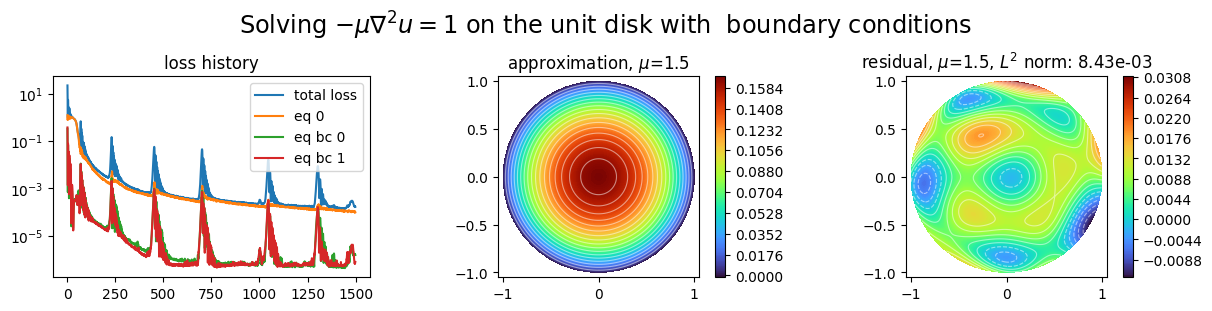

In [7]:
plot_abstract_approx_spaces(
    (
        pinns.space,
    ),
    domain_x,
    domain_mu,
    loss=(
        pinns.losses,
    ),
    residual=(
        pinns.pde,
    ),
    draw_contours=True,
    n_drawn_contours=20,
    parameters_values="mean",
    title=r"Solving $-\mu\nabla^2 u = 1$ on the unit disk with  boundary conditions",
)
plt.show()

## Questions
a) Change the disk into the square $\Omega=]0,1[^2$.

b) Define a manufactured solution such that $u=sin(x+y)$ is solution.

c) Implement and compare.